# Non-Gaussian Markov GP inference — Laplace, Gauss–Newton, posterior linearisation and EP

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/ssm/markov_gp_nongauss.ipynb)

`MarkovGPPrior` gives linear-time inference for a GP over one axis, $\mathcal{O}(N\,d^3)$ rather than $\mathcal{O}(N^3)$, through the Kalman filter and RTS smoother. That recursion needs a Gaussian likelihood. Many geoscience variables are not Gaussian: a day is wet or dry, a satellite counts plume detections, a sensor series has spikes. `pyrox_ssm` ships four strategies that keep the linear-time recursion for such likelihoods by replacing each non-Gaussian likelihood term with a Gaussian *site*.

This notebook explains how the four strategies differ, fits all four to three likelihoods (Bernoulli, Poisson and Student-t), compares their fits, convergence and cost, and ends with guidance on which strategy suits which kind of geoscience variable.

## Setup

Detect Colab and install `pyrox-gp[colab]` (which pulls in `matplotlib` and `watermark`) and `pyrox-ssm` only when running there. The likelihoods come from `pyrox_gp`; the Markov prior and the strategies come from `pyrox_ssm`.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
            "pyrox-ssm @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-ssm",
        ],
        check=True,
    )

In [2]:
import time
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from pyrox_gp import BernoulliLikelihood, PoissonLikelihood, StudentTLikelihood
from pyrox_ssm import (
    ExpectationPropagationMarkov,
    GaussNewtonMarkovInference,
    LaplaceMarkovInference,
    MarkovGPPrior,
    MaternSDE,
    PosteriorLinearizationMarkov,
)


jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,numpyro,pyrox,matplotlib")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
pyrox     : 0.2.1
matplotlib: 3.10.9

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. One loop, four ways to refresh a site

Every strategy approximates the likelihood term of observation $n$ by a Gaussian site in the latent $f_n = f(t_n)$,

$$t_n(f_n) \propto \exp\bigl(\lambda_n f_n - \tfrac12 \Lambda_n f_n^2\bigr) \quad \Leftrightarrow\quad \mathcal{N}\bigl(\tilde y_n \mid f_n,\; 1/\Lambda_n\bigr), \qquad \tilde y_n = \lambda_n / \Lambda_n,$$

so that the sites look like Gaussian *pseudo-observations* $\tilde y_n$ with noise variance $1/\Lambda_n$. One iteration then has two steps:

1. run the Kalman filter and RTS smoother on the pseudo-observations, which gives the marginal posteriors $q(f_n) = \mathcal{N}(m_n, V_n)$ in $\mathcal{O}(N\,d^3)$;
2. refresh every site $(\lambda_n, \Lambda_n)$ from the likelihood $p(y_n \mid f_n)$ and the current posterior.

The strategies differ only in step 2. Write $g_n$ and $h_n$ for the first and second derivatives of $\log p(y_n \mid f_n)$ in $f_n$, and $q_{\setminus n}(f_n)$ for the *cavity*, the posterior marginal with site $n$ divided out.

| Strategy | Site refresh | Literature |
|---|---|---|
| `LaplaceMarkovInference` | Newton step at the current mean: $\Lambda_n = \max(-h_n(m_n), \epsilon)$, $\lambda_n = \Lambda_n m_n + g_n(m_n)$, with floor $\epsilon = 10^{-6}$ | Nickisch, Solin & Grigorievskiy (2018); Rue, Martino & Chopin (2009) |
| `GaussNewtonMarkovInference` | the same Newton step with a strict floor $\epsilon = 10^{-3}$, so every site keeps a usable precision | Wilkinson, Särkkä & Solin (2023) |
| `PosteriorLinearizationMarkov` | the Newton step with $g_n$ and $h_n$ *averaged over the cavity*, $\mathbb{E}_{q_{\setminus n}}[g_n]$ and $\mathbb{E}_{q_{\setminus n}}[h_n]$, by 20-point Gauss–Hermite quadrature | García-Fernández et al. (2015); Wilkinson, Särkkä & Solin (2023) |
| `ExpectationPropagationMarkov` | match the mean and variance of the *tilted* distribution $q_{\setminus n}(f_n)\,p(y_n \mid f_n)$, then divide out the cavity | Minka (2001); Wilkinson et al. (2020) |

Laplace and Gauss–Newton look at the likelihood at one point, the current mean; posterior linearisation and EP look at it across the cavity's spread, which costs a quadrature per site but sees curvature that a point evaluation misses. In pyrox, `GaussNewtonMarkovInference` is exactly `LaplaceMarkovInference` with the larger floor; the Gauss–Newton methods of Wilkinson, Särkkä & Solin (2023) reach the same goal, a positive site precision, by approximating the Hessian instead. Posterior linearisation and EP start damped (`damping=0.5`); Laplace and Gauss–Newton take full steps (`damping=1.0`) unless told otherwise.

## 2. Three likelihoods, three geoscience stand-ins

All three data sets share one irregular grid of $N = 80$ times on $[0, 5]$ and a known latent $f(t)$, so every fit can be scored against the truth.

- **Bernoulli, logit link**: occurrence data, such as whether a day is wet or dry at a rain gauge. $y_n \sim \mathrm{Bernoulli}(\sigma(f(t_n)))$ with $f(t) = 1.5 \sin 2t + 0.3 \cos 7t$.
- **Poisson, log link**: event counts, such as lightning flashes or fire detections per interval. $y_n \sim \mathrm{Poisson}(e^{f(t_n)})$ with $f(t) = 1 + 1.2 \sin 1.5t$.
- **Student-t**: a smooth signal measured by a sensor that sometimes spikes, such as a retrieval contaminated by cloud. $y_n = \sin 2t_n + 0.1\,\varepsilon_n$ with 8 of the 80 values shifted by $\pm 2.5$ to $\pm 4$, fitted with a Student-t likelihood ($\nu = 3$, scale 0.1).

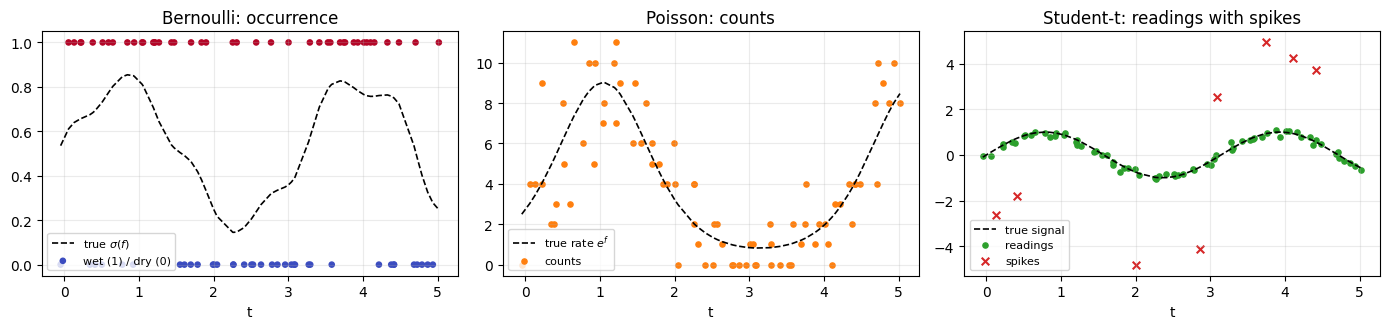

In [4]:
N = 80
times = jnp.sort(
    jnp.linspace(0.0, 5.0, N) + 0.04 * jax.random.normal(jax.random.PRNGKey(1), (N,))
)

f_bern = 1.5 * jnp.sin(2.0 * times) + 0.3 * jnp.cos(7.0 * times)
y_bern = (
    jax.random.uniform(jax.random.PRNGKey(7), (N,)) < jax.nn.sigmoid(f_bern)
).astype(jnp.float64)

f_pois = 1.0 + 1.2 * jnp.sin(1.5 * times)
y_pois = jax.random.poisson(jax.random.PRNGKey(3), jnp.exp(f_pois)).astype(jnp.float64)

f_st = jnp.sin(2.0 * times)
outliers = jax.random.choice(jax.random.PRNGKey(6), N, (8,), replace=False)
shifts = jnp.array([3.0, -3.0, 2.5, -2.5, 4.0, -4.0, 3.5, -3.5])
y_st = (
    (f_st + 0.1 * jax.random.normal(jax.random.PRNGKey(5), (N,)))
    .at[outliers]
    .add(shifts)
)

cases = {
    "Bernoulli": {
        "likelihood": BernoulliLikelihood(),
        "y": y_bern,
        "f": f_bern,
        "sde": MaternSDE(variance=1.0, lengthscale=0.4, order=1),
    },
    "Poisson": {
        "likelihood": PoissonLikelihood(),
        "y": y_pois,
        "f": f_pois,
        "sde": MaternSDE(variance=1.0, lengthscale=0.8, order=1),
    },
    "Student-t": {
        "likelihood": StudentTLikelihood(df=3.0, scale=0.1),
        "y": y_st,
        "f": f_st,
        "sde": MaternSDE(variance=1.0, lengthscale=0.5, order=1),
    },
}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(times, jax.nn.sigmoid(f_bern), "k--", lw=1.2, label=r"true $\sigma(f)$")
axes[0].scatter(
    times, y_bern, c=y_bern, cmap="coolwarm", s=14, label="wet (1) / dry (0)"
)
axes[0].set_title("Bernoulli: occurrence")
axes[1].plot(times, jnp.exp(f_pois), "k--", lw=1.2, label=r"true rate $e^{f}$")
axes[1].scatter(times, y_pois, s=14, color="C1", label="counts")
axes[1].set_title("Poisson: counts")
is_out = jnp.zeros(N, dtype=bool).at[outliers].set(True)
axes[2].plot(times, f_st, "k--", lw=1.2, label="true signal")
axes[2].scatter(times[~is_out], y_st[~is_out], s=14, color="C2", label="readings")
axes[2].scatter(
    times[is_out], y_st[is_out], s=30, marker="x", color="C3", label="spikes"
)
axes[2].set_title("Student-t: readings with spikes")
for ax in axes:
    ax.set_xlabel("t")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

## 3. Fit all four strategies

The helper below fits each strategy and records whether it converged, how many filter-smoother iterations it used, its wall time, the RMSE of its posterior mean against the true latent, and its largest gap from the EP posterior mean. The strategies run as eager Python loops that compile new code at every iteration, so wall time here is mostly compilation and roughly proportional to the iteration count; read it as relative cost on this machine, not as a benchmark. Every fit also reports `log_marginal_approx`, but its meaning is strategy-specific, so the tables leave it out.

In [5]:
def default_strategies(max_iter: int = 50) -> dict:
    """The four strategies with their default damping and floors."""
    return {
        "Laplace": LaplaceMarkovInference(max_iter=max_iter, tol=1e-6),
        "Gauss-Newton": GaussNewtonMarkovInference(max_iter=max_iter, tol=1e-6),
        "Post. lin.": PosteriorLinearizationMarkov(max_iter=max_iter, tol=1e-6),
        "EP": ExpectationPropagationMarkov(max_iter=max_iter, tol=1e-6),
    }


def fit_all(case: dict, strategies: dict) -> dict:
    """Fit every strategy to one case; return the fits and a summary per strategy."""
    prior = MarkovGPPrior(case["sde"], times)
    results = {}
    for name, strategy in strategies.items():
        t0 = time.perf_counter()
        cond = strategy.fit(prior, case["likelihood"], case["y"])
        seconds = time.perf_counter() - t0
        # The eager fit loops compile new code at every iteration and keep it
        # cached; clearing the cache after each fit keeps one kernel's memory
        # bounded across the many fits in this notebook.
        jax.clear_caches()
        rmse = float(jnp.sqrt(jnp.mean((cond.q_mean - case["f"]) ** 2)))
        results[name] = {"cond": cond, "seconds": seconds, "rmse": rmse}
    if "EP" in results:
        ep_mean = results["EP"]["cond"].q_mean
        for res in results.values():
            res["gap_ep"] = float(jnp.max(jnp.abs(res["cond"].q_mean - ep_mean)))
    return results


def show(results: dict) -> None:
    """Print one row per strategy."""
    print(
        f"{'strategy':<16}{'converged':>10}{'iters':>7}{'seconds':>9}{'RMSE':>8}"
        f"{'max |m - m_EP|':>16}"
    )
    for name, res in results.items():
        cond = res["cond"]
        gap = res.get("gap_ep", float("nan"))
        print(
            f"{name:<16}{cond.converged!s:>10}{cond.n_iter:>7}{res['seconds']:>9.1f}"
            f"{res['rmse']:>8.3f}{gap:>16.4f}"
        )


t_star = jnp.linspace(-0.3, 6.5, 300)
colors = {"Laplace": "C0", "Gauss-Newton": "C1", "Post. lin.": "C2", "EP": "C3"}
styles = {"Laplace": "-", "Gauss-Newton": ":", "Post. lin.": "-", "EP": "--"}

### 3.1 Bernoulli: occurrence

strategy         converged  iters  seconds    RMSE  max |m - m_EP|
Laplace               True      6      9.6   0.627          0.0603
Gauss-Newton          True      6      8.6   0.627          0.0603
Post. lin.            True     20     16.4   0.612          0.0013
EP                    True     20     15.3   0.612          0.0000


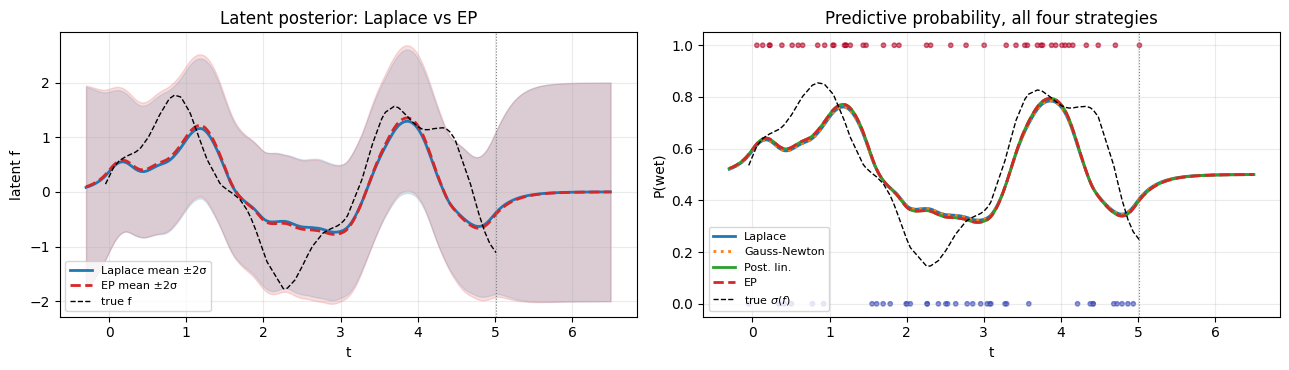

In [6]:
bern = fit_all(cases["Bernoulli"], default_strategies())
show(bern)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for name, res in bern.items():
    m, v = (np.asarray(a) for a in res["cond"].predict(t_star))
    axes[1].plot(
        t_star, jax.nn.sigmoid(m), color=colors[name], ls=styles[name], lw=2, label=name
    )
    if name in ("Laplace", "EP"):
        sd = np.sqrt(np.maximum(v, 0.0))
        axes[0].fill_between(
            t_star, m - 2 * sd, m + 2 * sd, color=colors[name], alpha=0.15
        )
        axes[0].plot(
            t_star,
            m,
            color=colors[name],
            ls=styles[name],
            lw=2,
            label=f"{name} mean ±2σ",
        )
axes[0].plot(times, f_bern, "k--", lw=1, label="true f")
axes[0].set_ylabel("latent f")
axes[0].set_title("Latent posterior: Laplace vs EP")
axes[1].plot(times, jax.nn.sigmoid(f_bern), "k--", lw=1, label=r"true $\sigma(f)$")
axes[1].scatter(times, y_bern, c=y_bern, cmap="coolwarm", s=10, alpha=0.6)
axes[1].set_ylabel("P(wet)")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_title("Predictive probability, all four strategies")
for ax in axes:
    ax.axvline(times[-1], color="grey", ls=":", lw=0.8)
    ax.set_xlabel("t")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

The Bernoulli likelihood is log-concave ($h_n < 0$ everywhere), so all four strategies converge. Laplace and Gauss–Newton give identical fits: the Bernoulli curvature $\sigma(f)(1 - \sigma(f))$ stays far above both floors here, so the floors never act. Posterior linearisation and EP agree with each other closely, and both differ from Laplace by a few hundredths in the mean: Laplace centres each site on the mode of the likelihood at one point, while the other two average over the cavity. This is the pattern Kuss & Rasmussen (2005) report for GP classification, where EP's posterior is closer to the MCMC reference than Laplace's. Laplace pays for its bias with speed: it needs the fewest iterations and no quadrature. Past the dotted line (the last observation) every posterior relaxes to the prior mean of zero and the prior variance, because no observation constrains $f$ there.

### 3.2 Poisson: counts

strategy         converged  iters  seconds    RMSE  max |m - m_EP|
Laplace               True     10      9.6   0.179          0.0607
Gauss-Newton          True     10     10.0   0.179          0.0607
Post. lin.            True     26     18.9   0.203          0.0263
EP                    True     21     16.0   0.203          0.0000


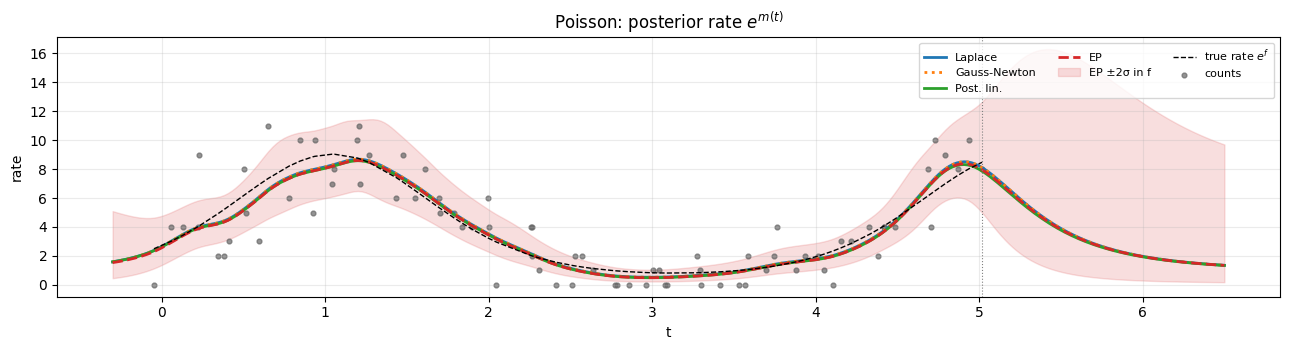

In [7]:
pois = fit_all(cases["Poisson"], default_strategies())
show(pois)

fig, ax = plt.subplots(figsize=(13, 3.6))
for name, res in pois.items():
    m, v = (np.asarray(a) for a in res["cond"].predict(t_star))
    ax.plot(t_star, np.exp(m), color=colors[name], ls=styles[name], lw=2, label=name)
    if name == "EP":
        sd = np.sqrt(np.maximum(v, 0.0))
        ax.fill_between(
            t_star,
            np.exp(m - 2 * sd),
            np.exp(m + 2 * sd),
            color=colors[name],
            alpha=0.15,
            label="EP ±2σ in f",
        )
ax.plot(times, jnp.exp(f_pois), "k--", lw=1, label=r"true rate $e^{f}$")
ax.scatter(times, y_pois, s=12, color="0.4", alpha=0.7, label="counts")
ax.axvline(times[-1], color="grey", ls=":", lw=0.8)
ax.set_xlabel("t")
ax.set_ylabel("rate")
ax.set_title(r"Poisson: posterior rate $e^{m(t)}$")
ax.grid(alpha=0.25)
ax.legend(fontsize=8, loc="upper right", ncol=3)
fig.tight_layout()
plt.show()

The Poisson likelihood with a log link is also log-concave ($h_n = -e^{f_n}$), and the picture repeats: everything converges, Laplace and Gauss–Newton coincide, and posterior linearisation and EP sit together a few hundredths away from them. With counts this large the likelihood is close to Gaussian in $f$, so the choice of strategy matters little; it matters more for sparse counts, where many zeros make the likelihood strongly skewed.

### 3.3 Student-t: readings with spikes

strategy         converged  iters  seconds    RMSE  max |m - m_EP|
Laplace              False     50     29.4   6.431         10.4889
Gauss-Newton         False     50     29.1   8.599         14.3758
Post. lin.           False     50     30.4   0.071          0.1671
EP                    True     35     22.1   0.070          0.0000


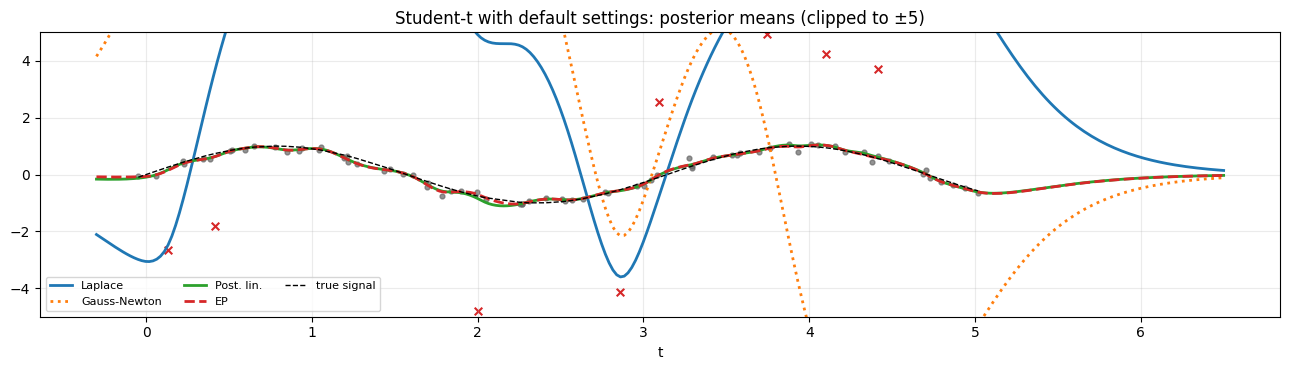

In [8]:
st = fit_all(cases["Student-t"], default_strategies())
show(st)


def plot_student_t(results: dict, title: str) -> None:
    """Posterior means of every strategy against the spiky readings."""
    fig, ax = plt.subplots(figsize=(13, 3.8))
    for name, res in results.items():
        m, _ = (np.asarray(a) for a in res["cond"].predict(t_star))
        ax.plot(
            t_star,
            m,
            color=colors.get(name.split(",")[0], "C4"),
            ls=styles.get(name.split(",")[0], "-"),
            lw=2,
            label=name,
        )
    ax.plot(times, f_st, "k--", lw=1, label="true signal")
    ax.scatter(times[~is_out], y_st[~is_out], s=12, color="0.4", alpha=0.7)
    ax.scatter(times[is_out], y_st[is_out], s=30, marker="x", color="C3")
    ax.set_ylim(-5, 5)
    ax.set_xlabel("t")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="lower left", ncol=3)
    fig.tight_layout()
    plt.show()


plot_student_t(st, "Student-t with default settings: posterior means (clipped to ±5)")

Here the strategies part ways. The Student-t log-likelihood is not log-concave: for a reading far from the current mean, $h_n > 0$. Laplace and Gauss–Newton then floor the site precision to $\epsilon$, so the site contributes its full gradient $g_n$ to $\lambda_n = \Lambda_n m_n + g_n$ with almost no curvature to balance it. Taking full steps, they overshoot and do not converge in 50 iterations; their means are far from the signal. Posterior linearisation and EP average the curvature over the cavity, where the well-behaved readings dominate, and both track the true signal through the spikes. Posterior linearisation has not met the tolerance after 50 iterations although its mean is already accurate; EP converges.

The standard remedy for Laplace is damping, a shorter step along the same direction. The cell below refits Laplace and Gauss–Newton with `damping=0.3` and gives posterior linearisation more iterations.

strategy         converged  iters  seconds    RMSE  max |m - m_EP|
Laplace, damping 0.3      True     51     28.2   0.072             nan
Gauss-Newton, damping 0.3      True     50     28.5   0.072             nan
Post. lin., 100 iterations      True     81     45.7   0.071             nan


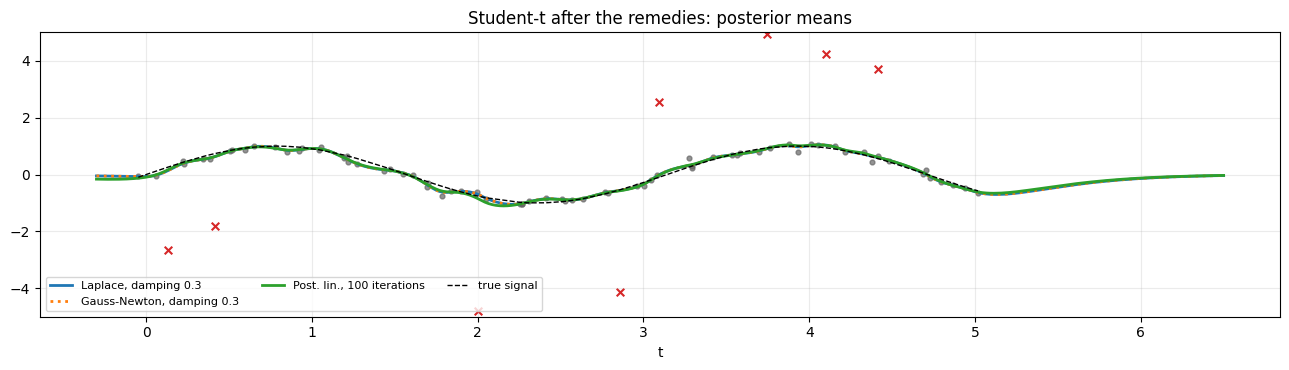

In [9]:
remedies = {
    "Laplace, damping 0.3": LaplaceMarkovInference(max_iter=100, tol=1e-6, damping=0.3),
    "Gauss-Newton, damping 0.3": GaussNewtonMarkovInference(
        max_iter=100, tol=1e-6, damping=0.3
    ),
    "Post. lin., 100 iterations": PosteriorLinearizationMarkov(max_iter=100, tol=1e-6),
}
st_fixed = fit_all(cases["Student-t"], remedies)
show(st_fixed)
plot_student_t(st_fixed, "Student-t after the remedies: posterior means")

With damping, Laplace and Gauss–Newton recover the signal, at the price of many more iterations than they need on the log-concave cases. Robust regression with a Student-t likelihood is a known hard case for every approximation: Jylänki, Vanhatalo & Vehtari (2011) show that EP itself can fail to converge on it and needs damping or a double-loop scheme, which is why pyrox's EP starts damped.

## 4. Convergence and cost

Every strategy costs one filter-smoother pass per iteration, $\mathcal{O}(I\,N\,d^3)$ for $I$ iterations. Posterior linearisation and EP add a 20-node Gauss–Hermite quadrature per site, which is $\mathcal{O}(N)$ and small next to the smoother for this $d$. Iterations therefore drive the cost, and the iteration count depends on the likelihood and on the damping far more than on the strategy's per-step work. In this eager implementation each iteration also pays for compilation, which is why a fit of 80 points takes seconds.

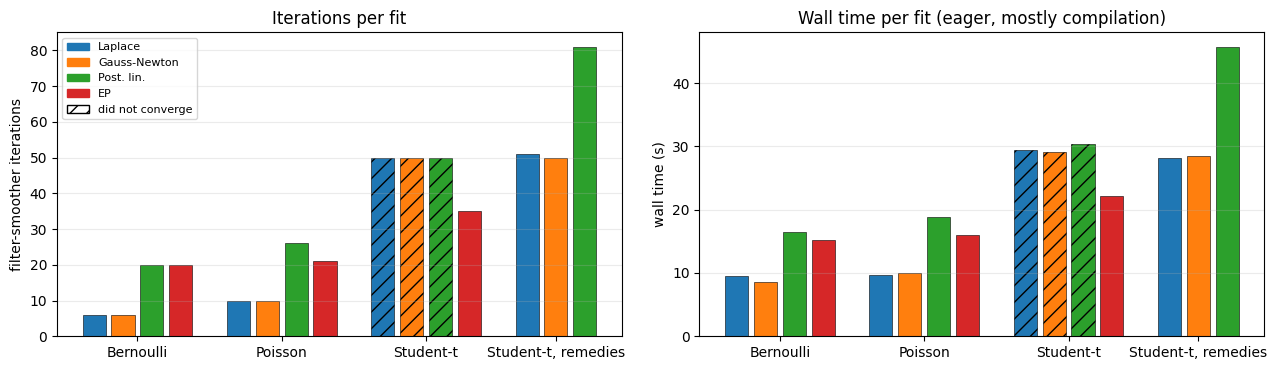

In [10]:
summary = {
    "Bernoulli": bern,
    "Poisson": pois,
    "Student-t": st,
    "Student-t, remedies": st_fixed,
}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
offset = 0
labels, positions = [], []
for case_name, results in summary.items():
    for k, (name, res) in enumerate(results.items()):
        x = offset + k
        base = name.split(",")[0]
        hatch = "" if res["cond"].converged else "//"
        for ax, value in zip(axes, (res["cond"].n_iter, res["seconds"]), strict=True):
            ax.bar(
                x,
                value,
                color=colors.get(base, "C4"),
                hatch=hatch,
                edgecolor="k",
                lw=0.4,
            )
    positions.append(offset + (len(results) - 1) / 2)
    labels.append(case_name)
    offset += len(results) + 1
for ax, ylabel in zip(
    axes, ("filter-smoother iterations", "wall time (s)"), strict=True
):
    ax.set_xticks(positions, labels)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25, axis="y")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
handles.append(
    plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor="k", hatch="//")
)
axes[0].legend(
    handles, [*colors.keys(), "did not converge"], fontsize=8, loc="upper left"
)
axes[0].set_title("Iterations per fit")
axes[1].set_title("Wall time per fit (eager, mostly compilation)")
fig.tight_layout()
plt.show()

On the log-concave cases Laplace and Gauss–Newton converge in the fewest iterations, because a full Newton step is the right step when the curvature is trustworthy; the damped posterior linearisation and EP take two to three times as many. On the Student-t case the ordering flips: the undamped Newton strategies run to the iteration limit without converging, and only EP converges with its defaults.

## 5. Which strategy for which geoscience variable

The deciding property is whether the log-likelihood is concave in $f$. If it is, every strategy converges and the choice trades speed (Laplace) against accuracy of the posterior moments (posterior linearisation, EP). If it is not, the point-wise Newton strategies need damping and care, and the cavity-averaging strategies are the safer default.

| Variable | Likelihood | Log-concave in $f$? | Suggested strategy | Literature |
|---|---|---|---|---|
| Precipitation occurrence (wet or dry day) | Bernoulli, logit link | yes | Laplace for speed; EP or posterior linearisation when the probabilities themselves matter | Stern & Coe (1984); Kuss & Rasmussen (2005) |
| Event counts: lightning flashes, fire detections, plume detections per overpass | Poisson, log link (a log-Gaussian Cox process in time) | yes | Laplace, as in INLA; EP for sparse counts with many zeros | Møller, Syversveen & Waagepetersen (1998); Rue, Martino & Chopin (2009) |
| Sensor or retrieval series with spikes (cloud contamination, instrument glitches) | Student-t | no | EP; Laplace only with damping | Jylänki, Vanhatalo & Vehtari (2011) |
| Any of the above with gaps (cloudy days, outages) | any, with `mask=` | — | any; a masked site holds zero naturals and the filter skips it | — |

**Where these strategies do well.**

- Long records: each iteration is linear in $N$, so a decade of daily occurrence data or hourly counts is routine.
- Gaps: every strategy's `fit` takes `mask=`, so missing days need no imputation, and a masked fit equals the fit with those days removed.
- Forecasts: `predict` extends past the last observation and relaxes to the prior, which is the honest answer for a stationary kernel.

**What to look out for.**

1. **Undamped Newton steps on a non-log-concave likelihood.** Laplace and Gauss–Newton diverged on the Student-t case with their default full steps. Lower `damping` first; switch to EP if that is not enough.
2. **Laplace bias for binary data.** Laplace's posterior mean is shrunk relative to EP's (Kuss & Rasmussen, 2005). If you threshold predicted probabilities, for example to forecast wet days, the difference shows up in calibration.
3. **Gauss–Newton is a floor in pyrox, not a different Hessian.** On log-concave likelihoods it is identical to Laplace; its floor only changes sites whose curvature falls below $10^{-3}$.
4. **`log_marginal_approx` is not comparable across strategies.** Each strategy reports its own quantity, so do not use it to choose between them; compare predictions instead.
5. **The latent must be scalar per time.** All four strategies take a scalar-latent likelihood, one $f_n$ per observation.

## Summary

- All four strategies run the same filter-smoother loop and differ only in how they refresh each Gaussian site: at one point (Laplace, Gauss–Newton) or averaged over the cavity (posterior linearisation, EP).
- On log-concave likelihoods (Bernoulli, Poisson) all four converge; Laplace and Gauss–Newton are fastest, and posterior linearisation and EP agree closely with each other.
- On the non-log-concave Student-t likelihood, undamped Laplace and Gauss–Newton diverge; damping rescues them, and EP converges with its defaults.

**References.**

1. García-Fernández, Á. F., Svensson, L., Morelande, M. R. & Särkkä, S. (2015). *Posterior linearization filter: principles and implementation using sigma points.* IEEE Transactions on Signal Processing 63(20), 5561–5573.
2. Jylänki, P., Vanhatalo, J. & Vehtari, A. (2011). *Robust Gaussian process regression with a Student-t likelihood.* JMLR 12, 3227–3257.
3. Kuss, M. & Rasmussen, C. E. (2005). *Assessing approximate inference for binary Gaussian process classification.* JMLR 6, 1679–1704.
4. Minka, T. P. (2001). *Expectation propagation for approximate Bayesian inference.* UAI.
5. Møller, J., Syversveen, A. R. & Waagepetersen, R. P. (1998). *Log Gaussian Cox processes.* Scandinavian Journal of Statistics 25(3), 451–482.
6. Nickisch, H., Solin, A. & Grigorievskiy, A. (2018). *State space Gaussian processes with non-Gaussian likelihood.* ICML, PMLR 80, 3789–3798.
7. Rue, H., Martino, S. & Chopin, N. (2009). *Approximate Bayesian inference for latent Gaussian models by using integrated nested Laplace approximations.* JRSS B 71(2), 319–392.
8. Stern, R. D. & Coe, R. (1984). *A model fitting analysis of daily rainfall data.* JRSS A 147(1), 1–34.
9. Wilkinson, W. J., Chang, P. E., Andersen, M. R. & Solin, A. (2020). *State space expectation propagation: efficient inference schemes for temporal Gaussian processes.* ICML, PMLR 119, 10270–10281.
10. Wilkinson, W. J., Särkkä, S. & Solin, A. (2023). *Bayes-Newton methods for approximate Bayesian inference with PSD guarantees.* JMLR 24(83).